**Praktikum Week 09 Mata Kuliah Kecerdasan Buatan** <br>
Materi: Neural Network <br>
Nim   : 42324038 <br>
Nama  : Aditia Xaverius Arapenta Tarigan <br>
Prodi : D3-Teknologi Informasi

# Klasifikasi Gambar Objek dengan Neural Network (Dataset CIFAR-10)

Pada praktikum sebelumnya digunakan dataset **Fashion MNIST** (gambar pakaian, grayscale, 28x28).
Di tugas ini saya mengganti dataset menjadi **CIFAR-10**: 60.000 gambar **berwarna (RGB) 32x32** dari 10 kelas
objek sehari-hari (pesawat, mobil, burung, kucing, rusa, anjing, katak, kuda, kapal, truk).
Data sudah dibagi menjadi 50.000 data latih dan 10.000 data uji.

> Cara pakai di Google Colab: **Runtime > Run all**. Neural network ini cukup ringan, jadi runtime CPU biasa sudah cukup
> (GPU boleh diaktifkan lewat *Runtime > Change runtime type* kalau mau lebih cepat).

## 1. Import Library & Load Dataset

In [1]:
# TensorFlow, NumPy, dan Matplotlib sudah terpasang di Google Colab, jadi tidak perlu pip install.
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import cifar10

# Seed supaya hasil lebih konsisten setiap kali dijalankan
tf.keras.utils.set_random_seed(42)

# Load dataset CIFAR-10
(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

# Label bawaan berbentuk (N, 1), diratakan menjadi (N,) agar mudah dipakai
train_labels = train_labels.flatten()
test_labels = test_labels.flatten()

# Nama kelas CIFAR-10 (urutan sesuai label 0-9)
class_names = ['pesawat', 'mobil', 'burung', 'kucing', 'rusa',
               'anjing', 'katak', 'kuda', 'kapal', 'truk']

print("Bentuk data latih :", train_images.shape)   # (50000, 32, 32, 3)
print("Bentuk data uji   :", test_images.shape)    # (10000, 32, 32, 3)
print("Rentang nilai piksel:", train_images.min(), "-", train_images.max())
print("Jumlah data per kelas (latih):", np.bincount(train_labels))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2775s 16us/step
Bentuk data latih : (50000, 32, 32, 3)
Bentuk data uji   : (10000, 32, 32, 3)
Rentang nilai piksel: 0 - 255
Jumlah data per kelas (latih): [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


## 2. Melihat Contoh Gambar

Berbeda dengan Fashion MNIST, gambar CIFAR-10 berwarna (3 channel) dan resolusinya kecil sehingga objek
sering terlihat buram. Ini membuat klasifikasinya lebih sulit.

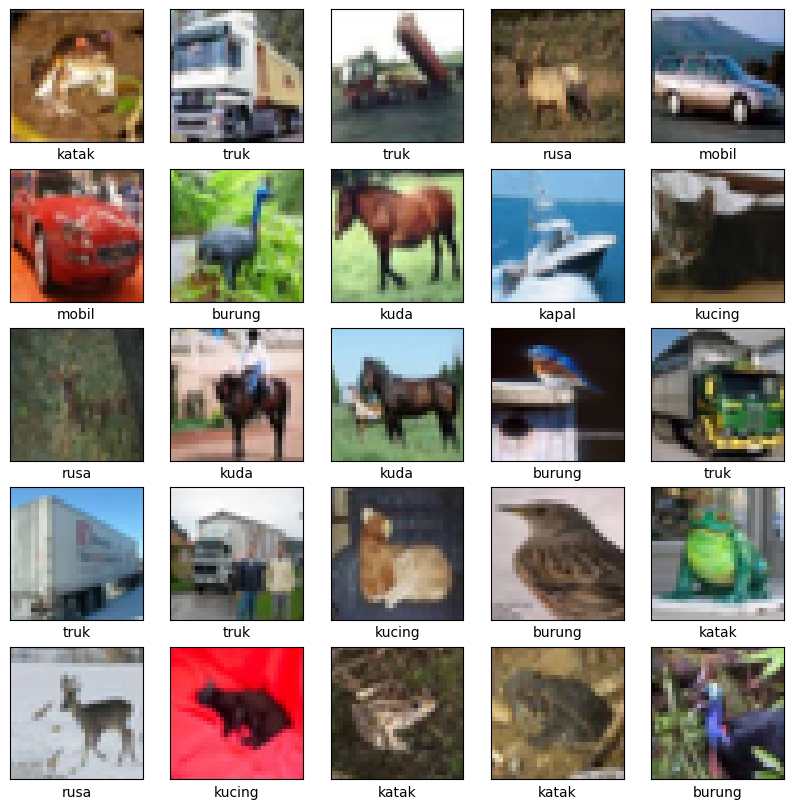

In [2]:
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])                    # tanpa cmap='gray' karena gambar berwarna
    plt.xlabel(class_names[train_labels[i]])
plt.show()

## 3. Preprocessing (Normalisasi)

Nilai piksel (0-255) dibagi 255 agar berada di rentang [0, 1]. Normalisasi membuat proses training lebih stabil dan cepat konvergen.

In [3]:
train_images = train_images / 255.0
test_images = test_images / 255.0
print("Rentang setelah normalisasi:", train_images.min(), "-", train_images.max())

Rentang setelah normalisasi: 0.0 - 1.0


## 4. Membangun Model Neural Network

Arsitektur dibuat dengan struktur yang sama seperti praktikum, yaitu `Flatten -> Dense -> Dense(softmax)`, dengan penyesuaian:

| Layer | Keterangan |
|---|---|
| `Input(32,32,3)` | Ukuran gambar CIFAR-10 (berwarna, 3 channel) |
| `Flatten` | Mengubah 32x32x3 menjadi vektor 3072 angka |
| `Dense(512, relu)` | Hidden layer 1, lebih besar karena gambar lebih kompleks |
| `Dropout(0.3)` | Mematikan 30% neuron secara acak saat training untuk mengurangi overfitting |
| `Dense(256, relu)` | Hidden layer 2 |
| `Dropout(0.3)` | Regularisasi lagi |
| `Dense(10, softmax)` | Output 10 kelas berupa probabilitas yang jumlahnya 1 |

In [4]:
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Flatten, Dense, Dropout

model = Sequential([
    Input(shape=(32, 32, 3)),
    Flatten(),                         # 32*32*3 = 3072 input
    Dense(512, activation='relu'),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')    # 10 kelas
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Kompilasi & Training Model

- **Optimizer `adam`**: mengatur update bobot secara adaptif.
- **Loss `sparse_categorical_crossentropy`**: cocok untuk klasifikasi multi-kelas dengan label berupa angka bulat (0-9).
- **Metrics `accuracy`**: persentase prediksi yang benar.
- **Validation split 10%**: 10% data latih disisihkan untuk validasi, sehingga data uji tetap murni untuk evaluasi akhir.
- **EarlyStopping**: training berhenti otomatis jika `val_loss` tidak membaik selama 5 epoch, lalu bobot terbaik dikembalikan.

In [5]:
from tensorflow.keras.callbacks import EarlyStopping

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(train_images, train_labels,
                    epochs=30,
                    batch_size=128,
                    validation_split=0.1,
                    callbacks=[early_stop])

Epoch 1/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 20s 49ms/step - accuracy: 0.2537 - loss: 2.0565 - val_accuracy: 0.3104 - val_loss: 1.8627
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - accuracy: 0.3056 - loss: 1.8951 - val_accuracy: 0.3622 - val_loss: 1.7853
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - accuracy: 0.3249 - loss: 1.8468 - val_accuracy: 0.3792 - val_loss: 1.7561
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - accuracy: 0.3430 - loss: 1.8091 - val_accuracy: 0.3886 - val_loss: 1.7426
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 21s 38ms/step - accuracy: 0.3547 - loss: 1.7822 - val_accuracy: 0.4096 - val_loss: 1.7021
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.3592 - loss: 1.7589 - val_accuracy: 0.4090 - val_loss: 1.6761
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - accuracy: 0.3662 - loss: 1.7373 - val_accuracy: 0.4162 - val_loss: 1.6705
Epoch 8/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.3764 - loss: 1.7270 - 

## 6. Evaluasi pada Data Uji

In [6]:
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=0)
print(f"Test loss    : {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")

Test loss    : 1.5631
Test accuracy: 0.4592 (45.92%)


## 7. Visualisasi Akurasi dan Loss

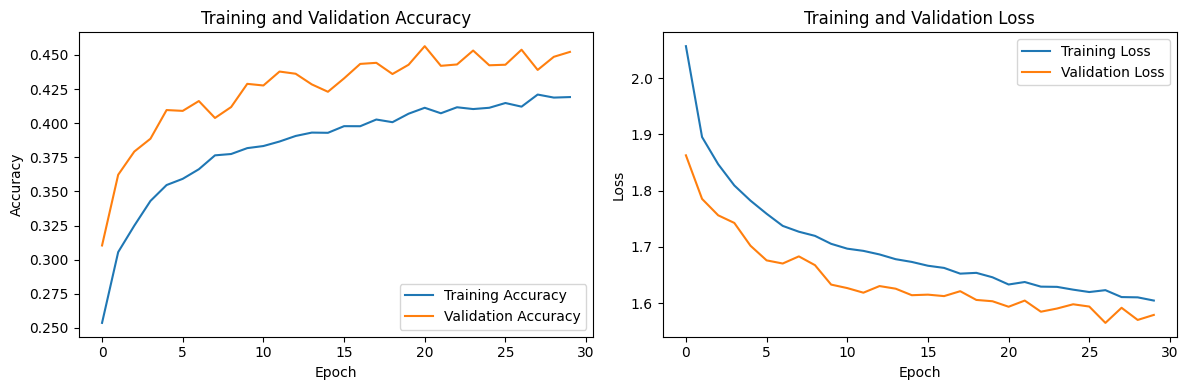

In [7]:
def plot_history(history):
    plt.figure(figsize=(12, 4))

    # Plot Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

plot_history(history)

## 8. Prediksi pada Gambar Uji

Setiap gambar diberi label hasil prediksi beserta tingkat keyakinan model (%), lalu label aslinya di dalam kurung.
**Biru = prediksi benar, merah = prediksi salah.**

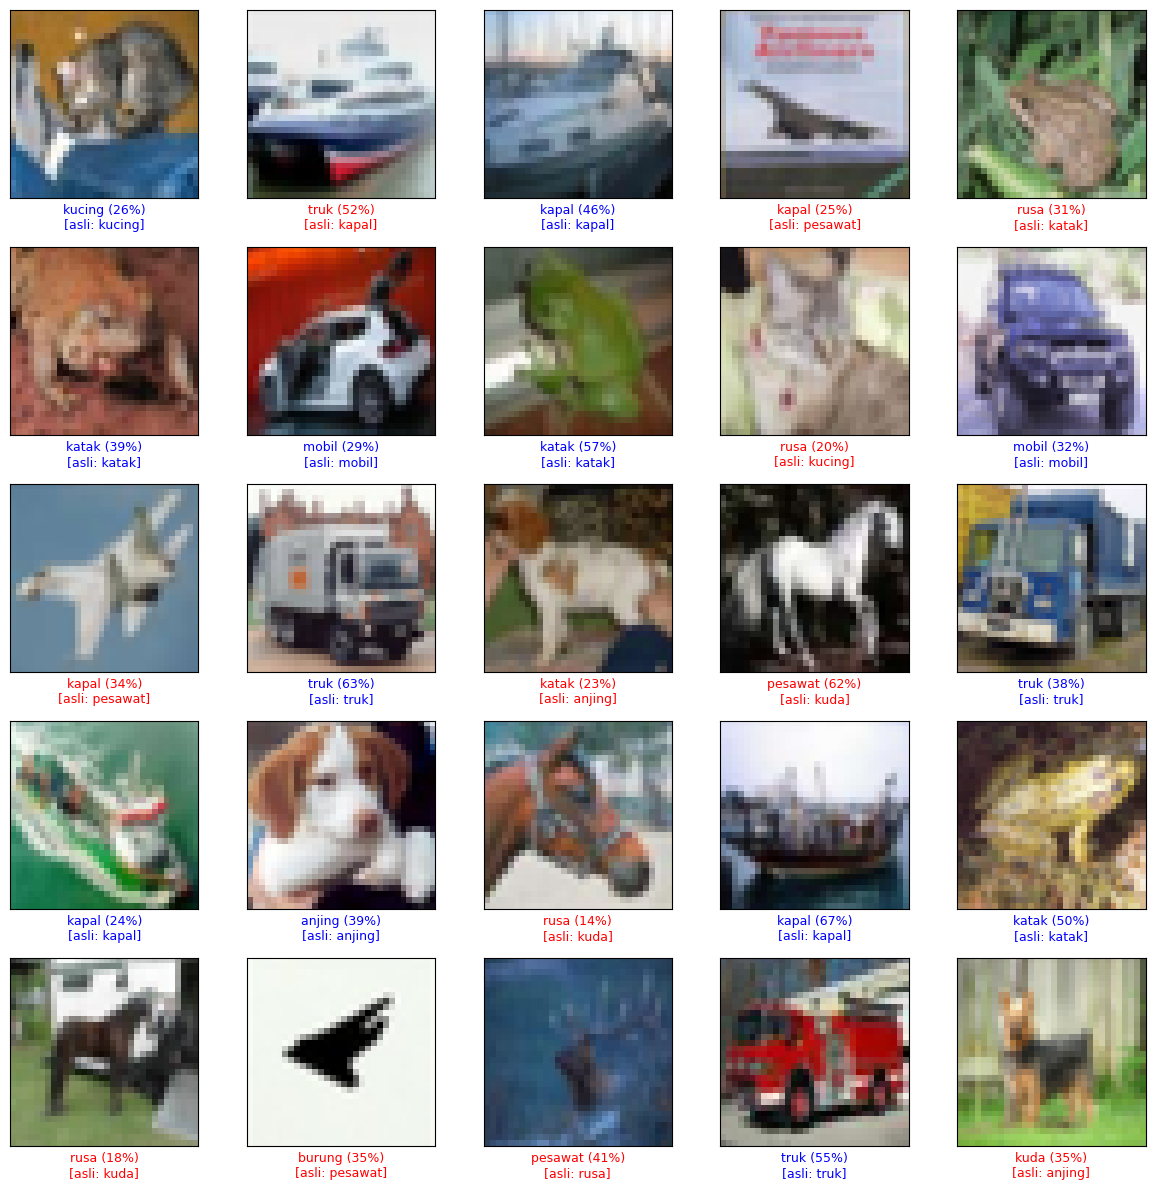

In [8]:
predictions = model.predict(test_images, verbose=0)

plt.figure(figsize=(12, 12))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(test_images[i])

    predicted_label = np.argmax(predictions[i])
    actual_label = test_labels[i]
    confidence = 100 * np.max(predictions[i])
    color = 'blue' if predicted_label == actual_label else 'red'

    plt.xlabel(f"{class_names[predicted_label]} ({confidence:.0f}%)\n[asli: {class_names[actual_label]}]",
               color=color, fontsize=9)
plt.tight_layout()
plt.show()

## 9. Analisis Tambahan: Confusion Matrix & Akurasi per Kelas

Confusion matrix menunjukkan kelas mana yang sering tertukar. Baris adalah label asli dan kolom adalah prediksi model.

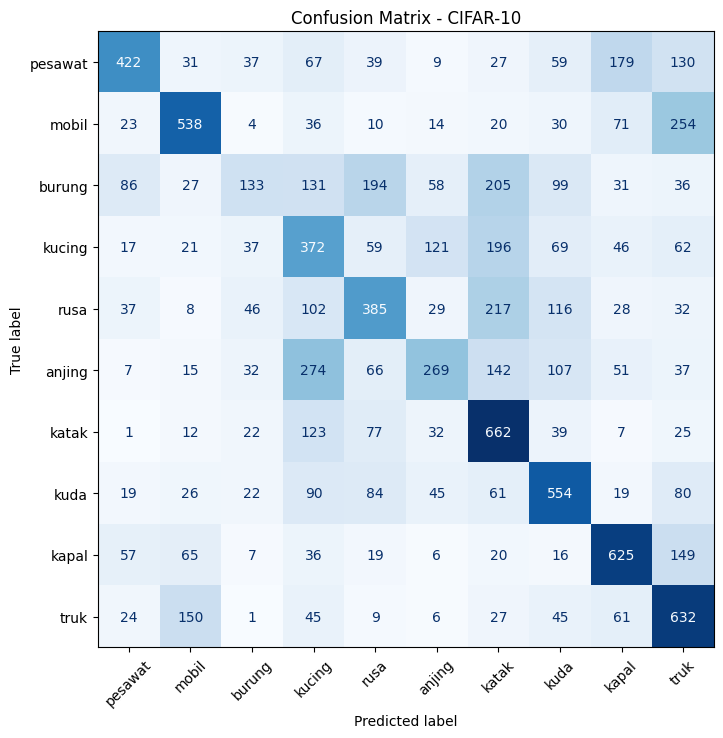

              precision    recall  f1-score   support

     pesawat       0.61      0.42      0.50      1000
       mobil       0.60      0.54      0.57      1000
      burung       0.39      0.13      0.20      1000
      kucing       0.29      0.37      0.33      1000
        rusa       0.41      0.39      0.40      1000
      anjing       0.46      0.27      0.34      1000
       katak       0.42      0.66      0.51      1000
        kuda       0.49      0.55      0.52      1000
       kapal       0.56      0.62      0.59      1000
        truk       0.44      0.63      0.52      1000

    accuracy                           0.46     10000
   macro avg       0.47      0.46      0.45     10000
weighted avg       0.47      0.46      0.45     10000



In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

y_pred = np.argmax(predictions, axis=1)

cm = confusion_matrix(test_labels, y_pred)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
plt.title('Confusion Matrix - CIFAR-10')
plt.show()

print(classification_report(test_labels, y_pred, target_names=class_names))

---
# Penjelasan Tugas

## A. Apa yang saya buat?
Saya membuat model **Neural Network (Multilayer Perceptron)** menggunakan TensorFlow/Keras untuk **mengklasifikasikan gambar berwarna
ke dalam 10 kategori objek** pada dataset **CIFAR-10**. Alur kerjanya sama dengan kode praktikum (Fashion MNIST), tetapi dengan dataset yang berbeda
dan beberapa penyesuaian.

## B. Perbandingan dengan kode praktikum

| Aspek | Praktikum (Fashion MNIST) | Tugas saya (CIFAR-10) |
|---|---|---|
| Isi gambar | Pakaian | Objek sehari-hari (hewan & kendaraan) |
| Ukuran gambar | 28x28, grayscale (1 channel) | 32x32, berwarna (3 channel) |
| Input setelah Flatten | 784 | 3.072 |
| Hidden layer | 1 layer, 128 neuron | 2 layer (512 dan 256 neuron) + Dropout |
| Training | 10 epoch tetap | Maks. 30 epoch dengan EarlyStopping |
| Validasi | Memakai data uji | `validation_split` 10% dari data latih |
| Tambahan | - | Nama kelas, warna prediksi benar/salah, confusion matrix, classification report |

## C. Penjelasan alur kode
1. **Load data**: `cifar10.load_data()` mengunduh dataset otomatis. Label diratakan dengan `.flatten()` karena bawaannya berbentuk `(N, 1)`.
2. **Visualisasi**: 25 gambar pertama ditampilkan untuk mengenali isi datanya.
3. **Normalisasi**: piksel dibagi 255 agar skalanya 0-1.
4. **Model**: `Flatten` meratakan gambar menjadi vektor, dua `Dense` dengan aktivasi **ReLU** mempelajari pola non-linear, **Dropout** mencegah model menghafal data latih, dan `Dense(10, softmax)` menghasilkan probabilitas 10 kelas.
5. **Compile & fit**: model dilatih dengan optimizer Adam dan loss sparse categorical crossentropy. EarlyStopping menghentikan training saat validasi tidak membaik.
6. **Evaluasi**: akurasi akhir dihitung pada 10.000 data uji yang belum pernah dilihat model.
7. **Plot history**: grafik akurasi dan loss per epoch untuk memeriksa overfitting.
8. **Prediksi**: `np.argmax` mengambil kelas dengan probabilitas tertinggi.
9. **Confusion matrix**: menunjukkan pola kesalahan model.

## D. Hasil dan analisis
*(Isi bagian ini dengan angka dari hasil run kamu sendiri.)*

- **Test accuracy**: `.....` %
- **Epoch berhenti di**: `.....`
- **Kelas paling mudah dikenali**: `.....` (biasanya kapal, mobil, truk, atau kuda)
- **Kelas paling sering salah**: `.....` (biasanya kucing yang tertukar dengan anjing)

Hal-hal yang biasanya terlihat pada hasil:
- Akurasi pada CIFAR-10 jauh lebih rendah dibanding Fashion MNIST (umumnya sekitar 50-55% dibanding sekitar 88%).
  Penyebabnya, gambar CIFAR-10 berwarna, memiliki latar belakang yang beragam, dan posisi serta ukuran objek bervariasi, sedangkan
  Fashion MNIST sederhana dan terpusat.
- Neural network biasa (Dense) meratakan gambar menjadi vektor, sehingga **informasi posisi antar piksel hilang**. Model tidak "melihat" bentuk, tepi, atau tekstur
  seperti manusia.
- Pada grafik, akurasi training cenderung naik lebih cepat daripada validasi. Jarak yang melebar menandakan **overfitting**, dan Dropout serta EarlyStopping dipakai untuk menekannya.
- Kelas yang mirip secara visual (kucing-anjing, mobil-truk, pesawat-kapal) paling sering tertukar, terlihat dari confusion matrix.

## E. Kesimpulan
Neural network sederhana mampu mempelajari pola dasar (warna dominan dan bentuk kasar) sehingga jauh lebih baik daripada tebakan acak (10%),
tetapi kurang cocok untuk data gambar yang kompleks. Untuk meningkatkan akurasi (misalnya ke 70-80% atau lebih), langkah lanjutan yang bisa dicoba adalah
**Convolutional Neural Network (CNN)** yang menjaga struktur spasial gambar, serta **data augmentation** dan **batch normalization**.